# Chapter 69: Externalities, Pigouvian Correction, and Common-Pool Resources

This notebook reruns four worked examples from the chapter: rent dissipation in an open-access fishery, a corrective (Pigouvian) tax, a prize contest with too many teams, and a shared basin. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def logistic_growth(X, r=0.5, K=100.0):
    """G(X) = r X (1 - X/K). Principle: gordon-open-access-rent-dissipation. Book (ch069): G(50) = 12.5, G(75) = 9.375."""
    return r * X * (1 - X / K)


def open_access_fishery(p, c, q=0.01, r=0.5, K=100.0, X=None):
    """Gordon-Schaefer fishery in steady state: growth rX(1 - X/K), harvest H = qEX.

    Principle: gordon-open-access-rent-dissipation. With X None the stock is the free-entry
    stock c / (q p) (zero profit); if that is at or above K no effort enters. Book (ch069):
    p = 10, c = 5 gives X_OA = 50, H = 12.5, E = 25, revenue = cost = 125, rent 0; X = 75 gives
    H 9.375, E 12.5, revenue 93.75, cost 62.50, rent 31.25; p = 20 gives X 25, H 9.375, E 37.5, 187.5.
    """
    if X is None:
        X = min(c / (q * p), K)
    H = logistic_growth(X, r, K)
    E = H / (q * X) if X > 0 else 0.0
    revenue, cost = p * H, c * E
    return {"X": X, "H": H, "E": E, "revenue": revenue, "cost": cost, "rent": revenue - cost}


def pigou_tax(damage, tax, mb=(100.0, 1.0), mpc=(20.0, 1.0)):
    """Linear market MB = a - bQ, MPC = c + dQ, constant external damage per unit, per-unit tax.

    Principle: pigouvian-correction. Book (ch069): MB = 100 - Q, MPC = 20 + Q, damage 12 gives Q^p = 40,
    MSC at Q^p = 72, Q* = 34, and a 12 tax gives Q_t = 34. Damage 5 gives Q* = 37.5.
    The welfare loss of the taxed quantity against Q* is the triangle between MB and MSC,
    0.5 |Q_t - Q*| (b + d)|Q_t - Q*| (derived; the book prints no loss figure).
    """
    a, b = mb
    c, d = mpc
    q_p = (a - c) / (b + d)
    q_star = (a - c - damage) / (b + d)
    q_t = (a - c - tax) / (b + d)
    gap = q_t - q_star
    return {"Q_p": q_p, "Q_star": q_star, "Q_t": q_t, "MB_p": a - b * q_p, "MSC_p": c + d * q_p + damage,
            "gap": gap, "loss": 0.5 * abs(gap) * (b + d) * abs(gap)}


def prize_contest(n, p, V, P, cost, direct_p=0.40, direct_cost=300_000.0):
    """n independent teams each succeeding with probability p, a prize P shared at random among winners.

    Principle: prize-incentives-contest-design. Book (ch069): V = 1,500,000, P = 1,000,000, cost 80,000,
    p = 0.25, n = 4 gives q_4 = 0.68359375, W_4 = 705,390.625, share 170,898.4375; n = 12 gives
    q_12 = 0.96832365 (rounded), share 80,693.64 and exact W_12 = 492,485.472 (the book prints
    492,485.475 from the rounded q_12). Direct contract W_D = 0.40 x 1,500,000 - 300,000 = 300,000.
    """
    q = 1 - (1 - p) ** n
    share = q * P / n
    return {"q": q, "total_cost": n * cost, "W": q * V - n * cost, "share": share, "enters": share >= cost,
            "margin": share - cost, "W_D": direct_p * V - direct_cost}


def commons_symmetric(N, k, a=20.0):
    """N identical users, benefit a x - x^2 each, shared depletion cost k X^2 split equally.

    Principle: tragedy-of-the-commons. Private FOC a - 2x - 2kx = 0, coordinated a - 2x - 2kNx = 0.
    Book (ch069): N = 4, k = 0.1 gives x^N = 9.09, X^N = 36.36, x* = 7.14, X* = 28.57,
    W^N = 264.46, W* = 285.71, gain 21.25, withdrawal cut 7.79.
    """
    def welfare(x):
        return N * (a * x - x * x) - k * (N * x) ** 2

    xn = a / (2 + 2 * k)
    xs = a / (2 + 2 * k * N)
    return {"xN": xn, "XN": N * xn, "x_star": xs, "X_star": N * xs, "WN": welfare(xn), "W_star": welfare(xs),
            "gain": welfare(xs) - welfare(xn), "cut": N * (xn - xs), "welfare": welfare}


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(logistic_growth=logistic_growth, open_access_fishery=open_access_fishery, pigou_tax=pigou_tax, prize_contest=prize_contest, commons_symmetric=commons_symmetric)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'gordon-open-access-rent-dissipation': {'r': 0.5,
                                         'K': 100,
                                         'q': 0.01,
                                         'p': 10,
                                         'c': 5,
                                         'X_OA': 50,
                                         'H': 12.5,
                                         'E': 25,
                                         'revenue': 125,
                                         'cost': 125,
                                         'rent': 0,
                                         'X_controlled': 75,
                                         'H_controlled': 9.375,
                                         'E_controlled': 12.5,
                                         'revenue_controlled': 93.75,
                                         'cost_controlled': 62.5,
                                         'rent_controlled': 31.25,
                                         'p_high': 20,
                                         'X_high': 25,
                                         'H_high': 9.375,
                                         'E_high': 37.5,
                                         'revenue_high': 187.5},
 'pigouvian-correction': {'mb': (100, 1),
                          'mpc': (20, 1),
                          'damage': 12,
                          'tax': 12,
                          'Q_p': 40,
                          'MB_p': 60,
                          'MSC_p': 72,
                          'Q_star': 34,
                          'Q_t': 34,
                          'output_cut': 6,
                          'damage_low': 5,
                          'Q_star_low': 37.5},
 'prize-incentives-contest-design': {'V': 1500000,
                                     'P': 1000000,
                                     'cost': 80000,
                                     'p': 0.25,
                                     'n': 4,
                                     'direct_p': 0.4,
                                     'direct_cost': 300000,
                                     'W_D': 300000,
                                     'q_4': 0.68359375,
                                     'total_cost_4': 320000,
                                     'W_4': 705390.625,
                                     'share_4': 170898.4375,
                                     'n_12': 12,
                                     'q_12': 0.96832365,
                                     'total_cost_12': 960000,
                                     'W_12_printed_as': 492485.475,
                                     'W_12_exact_2dp': 492485.47,
                                     'share_12': 80693.64,
                                     'margin_12': 693.64},
 'tragedy-of-the-commons': {'N': 4,
                            'k': 0.1,
                            'a': 20,
                            'xN': 9.09,
                            'XN': 36.36,
                            'x_star': 7.14,
                            'X_star': 28.57,
                            'WN': 264.46,
                            'W_star': 285.71,
                            'gain': 21.25,
                            'cut': 7.79},
 'constructed': {'gordon-open-access-rent-dissipation': {'p': [7.5, 15], 'c': [2.5, 7.5]},
                 'pigouvian-correction': {'damage': [0, 20], 'loss_d5_t12': 12.25},
                 'prize-incentives-contest-design': {'n': [1, 8], 'p': [0.15, 0.35]},
                 'tragedy-of-the-commons': {'N': [2, 8], 'k': [0.05, 0.2]}}}


def fx(x):
    """Two decimals when exact at two decimals, else four (so worked lines add up)."""
    return num(x, 2) if abs(x * 100 - round(x * 100)) < 1e-9 else num(x, 4)


def fs(x):
    """Two decimals when exact at two decimals, else six (step lines)."""
    return num(x, 2) if abs(x * 100 - round(x * 100)) < 1e-9 else num(x, 6)


def mx(x):
    """Money with the decimals needed to be exact (140.625 -> '$140.625'), so worked lines add up."""
    for k in (2, 3, 4):
        if abs(x * 10 ** k - round(x * 10 ** k)) < 1e-9:
            return money(x, k)
    return money(x, 4)


def pv(x):
    """Price or cost input: 7.5 -> '7.50', 10 -> '10'."""
    return num(x, 0) if float(x).is_integer() else num(x, 2)


def c_over(cost, price, q):
    """Zero-profit stock before the carrying-capacity cap."""
    return cost / (q * price)


def fishery_picture(price=10, cost=5):
    b = BV["gordon-open-access-rent-dissipation"]
    q, r, K, Xc = b["q"], b["r"], b["K"], b["X_controlled"]
    oa = public.open_access_fishery(price, cost, q, r, K)
    ct = public.open_access_fishery(price, cost, q, r, K, X=Xc)
    X = oa["X"]
    no_entry = oa["H"] == 0
    fig, (ax1, ax2) = new_figure(ncols=2)
    xs = np.linspace(0, K, 300)
    ax1.plot(xs, [public.logistic_growth(x, r, K) for x in xs], color=PALETTE["teal"], linewidth=2.2)
    mark(ax1, X, oa["H"], col="terracotta")
    mark(ax1, Xc, ct["H"], col="navy")
    ax1.text(0.03, 0.97, f"red point: open access, X = {num(X)}", transform=ax1.transAxes, ha="left", va="top",
             fontsize=10.5, color=PALETTE["terracotta"])
    ax1.text(0.03, 0.89, f"blue point: controlled, X = {num(Xc, 0)}", transform=ax1.transAxes, ha="left", va="top",
             fontsize=10.5, color=PALETTE["navy"])
    ax1.set_xlim(0, 108)
    ax1.set_ylim(-0.8, 17.5)
    ax1.set_xlabel("Fish stock X")
    ax1.set_ylabel("Growth G(X) = sustainable harvest")
    vals = [oa["revenue"], oa["cost"], ct["revenue"], ct["cost"]]
    pos = [0, 0.7, 2, 2.7]
    cols = [PALETTE["teal"], PALETTE["gold"], PALETTE["teal"], PALETTE["gold"]]
    ax2.bar(pos, vals, width=0.6, color=cols)
    for x, v in zip(pos, vals):
        ax2.annotate(tex_safe(money(v)), (x, v), xytext=(0, 4), textcoords="offset points", ha="center",
                     va="bottom", fontsize=10.5, color=PALETTE["ink"])
    ax2.set_xticks([0.35, 2.35], ["Open access", f"Controlled X = {num(Xc, 0)}"])
    top = max(vals + [1])
    ax2.set_ylim(0, top * 1.32)
    ax2.text(0.03, 0.97, "teal bars: revenue; gold bars: effort cost", transform=ax2.transAxes, ha="left", va="top",
             fontsize=10.5, color=PALETTE["ink"])
    ax2.text(0.03, 0.89, tex_safe(f"rent: {money(oa['rent'])} vs {mx(ct['rent'])}"), transform=ax2.transAxes,
             ha="left", va="top", fontsize=10.5, color=PALETTE["ink"])
    ax2.set_ylabel("Dollars per year")
    ax2.set_xlabel("Management")
    metrics = {"Open-access stock X_OA": fx(X), "Sustainable harvest": fx(oa["H"]), "Effort E": fx(oa["E"]),
               "Revenue": money(oa["revenue"]), "Effort cost": money(oa["cost"]), "Open-access rent": money(oa["rent"]),
               "Controlled harvest (X = 75)": fx(ct["H"]), "Controlled effort": fx(ct["E"]),
               "Controlled rent": money(ct["rent"])}
    if abs(X - Xc) < 1e-9 and not no_entry:
        ctl = ("so holding the stock at 75 earns no rent either: the open-access stock is already 75 (the red point "
               "sits under the blue one), a tie")
    elif ct["rent"] > 0:
        ctl = f"so holding the stock at 75 earns a rent of {mx(ct['rent'])} a year that free entry would burn"
    elif ct["rent"] < 0:
        ctl = (f"so at these prices holding the stock at 75 would lose {mx(-ct['rent'])} a year: this cost of "
               f"effort makes every harvest lose money, so leaving the stock unfished is the efficient choice")
    else:
        ctl = "so holding the stock at 75 earns no rent either"
    if no_entry:
        tie = abs(c_over(cost, price, q) - K) < 1e-9
        where = ("equals the carrying capacity 100: a unit of effort only breaks even on the untouched stock, which "
                 "does not grow" if tie else "is above the carrying capacity 100, so even the untouched stock cannot pay "
                 "for effort")
        oa_text = (f"The zero-profit stock c / (0.01 p) = {pv(cost)} / (0.01 x {pv(price)}) = {fx(c_over(cost, price, q))} "
                   f"{where}: harvest, effort and rent are all 0.")
        steps = [f"X_OA = {pv(cost)} / (0.01 x {pv(price)}) = {fx(c_over(cost, price, q))}, " + ("equal to K = 100" if abs(c_over(cost, price, q) - K) < 1e-9 else "above K = 100"),
                 "At X = 100 growth is 0.5 x 100 x (1 - 1) = 0, so no harvest and no effort",
                 f"Controlled: G(75) = 0.5 x 75 x 0.25 = 9.375; E = 9.375 / (0.01 x 75) = 12.5",
                 f"Controlled revenue = {pv(price)} x 9.375 = {mx(ct['revenue'])}; cost = {pv(cost)} x 12.5 = "
                 f"{money(ct['cost'])}",
                 f"Controlled rent = {mx(ct['revenue'])} - {money(ct['cost'])} = {mx(ct['rent'])}"]
    else:
        oa_text = (f"Free entry pushes the stock to where a unit of effort just pays: {pv(price)} x 0.01 x X = "
                   f"{pv(cost)}, so X_OA = {fx(X)}. Growth there is {fx(oa['H'])}, which needs effort "
                   f"{fs(oa['H'])} / (0.01 x {fs(X)}) = {fx(oa['E'])}. Revenue {money(oa['revenue'])} equals effort "
                   f"cost {money(oa['cost'])}, so the rent is {money(oa['rent'])}.")
        steps = [f"X_OA = {pv(cost)} / (0.01 x {pv(price)}) = {fs(X)}",
                 f"H = G(X_OA) = 0.5 x {fs(X)} x {fs(1 - X / K)} = {fx(oa['H'])}",
                 f"E = {fs(oa['H'])} / (0.01 x {fs(X)}) = {fx(oa['E'])}",
                 f"Revenue = {pv(price)} x {fs(oa['H'])} = {money(oa['revenue'])}; cost = {pv(cost)} x {fs(oa['E'])} = "
                 f"{money(oa['cost'])}; rent = {money(oa['rent'])}",
                 f"Controlled X = 75: revenue = {pv(price)} x 9.375 = {mx(ct['revenue'])}; cost = {pv(cost)} x 12.5 = "
                 f"{money(ct['cost'])}; rent = {mx(ct['rent'])}"]
    interp = (f"{oa_text} At the controlled stock of 75, growth is 9.375 and effort 12.5, giving revenue "
              f"{mx(ct['revenue'])} against cost {money(ct['cost'])}, {ctl}.")
    alt = (f"Left: the logistic growth curve with the open-access stock {fx(X)} (harvest {fx(oa['H'])}) and the "
           f"controlled stock 75 (harvest 9.375). Right: revenue and effort cost, {money(oa['revenue'])} and "
           f"{money(oa['cost'])} under open access, {mx(ct['revenue'])} and {money(ct['cost'])} when controlled.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def pigou_picture(damage=12, tax=12):
    r = public.pigou_tax(damage, tax)
    qp, qs, qt, loss, gap = r["Q_p"], r["Q_star"], r["Q_t"], r["loss"], r["gap"]
    fig, ax = new_figure()
    Q = np.linspace(0, 70, 200)
    ax.plot(Q, 100 - Q, color=PALETTE["navy"], linewidth=2.2)
    ax.plot(Q, 20 + Q, color=PALETTE["ink"], linewidth=1.8)
    label(ax, 6, 94, "MB = 100 - Q", col="navy", dx=0, dy=4)
    label(ax, 8, 28, "MPC = 20 + Q", col="ink", dx=4, dy=-8, va="top")
    if damage > 0:
        ax.plot(Q, 20 + Q + damage, color=PALETTE["terracotta"], linewidth=2.0)
        label(ax, 56, 76 + damage, f"MSC = MPC + {num(damage, 0)}", col="terracotta", dx=-6, dy=6, ha="right")
    if tax > 0 and tax != damage:
        ax.plot(Q, 20 + Q + tax, color=PALETTE["gold"], linewidth=1.8, linestyle="dashed")
        label(ax, 6, 26 + tax, f"MPC + tax {num(tax, 0)}", col="gold", dx=0, dy=6)
    if gap != 0:
        lo, hi = sorted([qt, qs])
        qq = np.linspace(lo, hi, 50)
        ax.fill_between(qq, 100 - qq, 20 + qq + damage, color=PALETTE["terracotta"], alpha=0.25, linewidth=0)
    mark(ax, qp, 100 - qp, "Q^p = " + ("taxed Q = " if qt == qp else "") + num(qp), col="ink", dx=8, dy=-10,
         va="top")
    mark(ax, qs, 100 - qs, ("Q* = taxed Q = " if qt == qs and qs != qp else "Q* = ") + num(qs), col="terracotta", dx=-8, dy=-10, ha="right", va="top")
    if qt != qs and qt != qp:
        mark(ax, qt, 100 - qt, f"taxed Q = {num(qt)}", col="gold", dx=8 if qt > qs else -8, dy=14,
             ha="left" if qt > qs else "right")
    ax.set_xlim(0, 70)
    ax.set_ylim(0, 110)
    ax.set_xlabel("Quantity Q (thousand units)")
    ax.set_ylabel("Dollars per unit")
    if gap > 0:
        verdict = f"output is {num(gap)} thousand units too high"
        short = "Too high"
    elif gap < 0:
        verdict = f"output is {num(-gap)} thousand units too low"
        short = "Too low"
    else:
        verdict = "output is efficient: the tax matches the damage"
        short = "Efficient"
    metrics = {"Untaxed output Q^p (000)": num(qp), "MSC at Q^p ($)": num(r["MSC_p"]), "Efficient Q* (000)": num(qs),
               "Taxed output (000)": num(qt), "Taxed vs efficient": short,
               "Welfare loss, derived ($000)": num(loss)}
    steps = ["Untaxed: 100 - Q = 20 + Q, so Q^p = 80 / 2 = 40.00",
             f"MSC at Q^p = 20 + 40 + {num(damage, 0)} = {num(r['MSC_p'])}",
             f"Efficient: 100 - Q = 20 + Q + {num(damage, 0)}, so Q* = {num(80 - damage, 0)} / 2 = {num(qs)}",
             f"Taxed: 100 - Q = 20 + Q + {num(tax, 0)}, so Q_t = {num(80 - tax, 0)} / 2 = {num(qt)}",
             f"Loss = 0.5 x {num(abs(gap))} x (2 x {num(abs(gap))}) = {num(loss)} thousand dollars (derived)"]
    interp = (f"With damage ${num(damage, 0)} per unit, the efficient quantity solves 100 - Q = 20 + Q + "
              f"{num(damage, 0)}, so Q* = (80 - {num(damage, 0)}) / 2 = {num(qs)} thousand. A ${num(tax, 0)} tax gives "
              f"(80 - {num(tax, 0)}) / 2 = {num(qt)} thousand, so "
              f"{verdict}. The shaded triangle between MB and MSC is the derived welfare loss, "
              f"{num(loss)} thousand dollars; the book does not print this figure.")
    alt = (f"Marginal benefit 100 - Q, marginal private cost 20 + Q and social cost with damage {num(damage, 0)}. "
           f"The untaxed market produces {num(qp)} thousand, the efficient quantity is {num(qs)} thousand and the "
           f"tax of {num(tax, 0)} gives {num(qt)} thousand; the welfare loss is {num(loss)} thousand dollars.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def prize_picture(teams=4, p=0.25):
    b = BV["prize-incentives-contest-design"]
    V, P, cost = b["V"], b["P"], b["cost"]
    r = public.prize_contest(teams, p, V, P, cost)
    ns = np.arange(1, 13)
    rows = [public.prize_contest(int(n), p, V, P, cost) for n in ns]
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.plot(ns, [x["W"] / 1000 for x in rows], color=PALETTE["teal"], linewidth=2.0, marker="o", markersize=4)
    hline(ax1, r["W_D"] / 1000, "direct contract W_D = 300,000", col="gold", x_frac=0.40, va="top")
    right = teams >= 8
    mark(ax1, teams, r["W"] / 1000, f"W = {num(r['W'] / 1000, 1)}k", col="terracotta", dx=-6 if right else 6, dy=10,
         ha="right" if right else "left")
    ws = [x["W"] / 1000 for x in rows] + [r["W_D"] / 1000]
    ax1.set_ylim(min(0, min(ws)) - 60, max(ws) + 140)
    ax1.set_xlim(0.5, 12.5)
    ax1.set_xlabel("Number of teams n")
    ax1.set_ylabel("Expected social value ($ thousand)")
    ax2.plot(ns, [x["share"] / 1000 for x in rows], color=PALETTE["navy"], linewidth=2.0, marker="o", markersize=4)
    hline(ax2, cost / 1000, "team cost 80,000", col="grey", x_frac=0.03, va="top")
    mark(ax2, teams, r["share"] / 1000, f"{num(r['share'] / 1000, 1)}k", col="terracotta",
         dx=-6 if right else 6, dy=8, ha="right" if right else "left")
    sh = [x["share"] / 1000 for x in rows]
    ax2.set_ylim(0, max(sh + [80]) * 1.15)
    ax2.set_xlim(0.5, 12.5)
    ax2.set_xlabel("Number of teams n")
    ax2.set_ylabel("Expected prize per team ($ thousand)")
    q10 = num(r["q"], 10)
    qv = r["q"] * V
    who = plural(teams, "team")
    subj = "the team wants" if teams == 1 else "teams want"
    enter = (f"covers its $80,000 cost, so {subj} to enter" if r["enters"]
             else f"falls short of its $80,000 cost, so {'the team would' if teams == 1 else 'teams would'} not enter")
    better = "above" if r["W"] > r["W_D"] else ("equal to" if r["W"] == r["W_D"] else "below")
    metrics = {"Success chance q_n": num(r["q"], 8), "Total team cost": money(r["total_cost"], 0),
               "Expected social value W_n": money(r["W"], 3), "Expected prize per team": money(r["share"]),
               "Direct contract W_D": money(r["W_D"], 0), "Teams enter": "Yes" if r["enters"] else "No"}
    steps = [f"q = 1 - {num(1 - p, 2)}^{teams} = {q10}",
             f"W = {q10} x 1,500,000 - {teams} x 80,000 = {num(qv, 3)} - {num(r['total_cost'], 0)} = {num(r['W'], 3)}",
             f"Prize per team = {q10} x 1,000,000 / {teams} = {num(r['share'])}",
             f"W_D = 0.40 x 1,500,000 - 300,000 = {num(r['W_D'], 0)}"]
    note = ""
    if teams == 12 and p == 0.25:
        note = (" The book rounds q_12 to 0.96832365 and prints W_12 as approximately 492,485.475; the exact value "
                "is 492,485.472.")
    interp = (f"With {who}{'' if teams == 1 else ' each'} succeeding with probability {num(p, 2)}, the chance that at least one succeeds is "
              f"1 - {num(1 - p, 2)}^{teams} = {num(r['q'], 8)}, so expected social value is {money(r['W'], 3)}, {better} the direct contract's "
              f"$300,000. {'The team' if teams == 1 else 'Each team'}'s expected prize, {money(r['share'])}, {enter}.{note}")
    alt = (f"Left: expected social value against the number of teams at success probability {num(p, 2)}, with "
           f"{who} giving {money(r['W'], 3)} against the direct contract's $300,000. Right: the expected prize per "
           f"team, {money(r['share'])} at {who}, against the $80,000 cost.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def commons_picture(users=4, k=0.1):
    r = public.commons_symmetric(users, k)
    xn, xs = r["xN"], r["x_star"]
    W = r["welfare"]
    fig, ax = new_figure()
    grid = np.linspace(0, 11, 300)
    ys = [W(x) for x in grid]
    ax.plot(grid, ys, color=PALETTE["teal"], linewidth=2.2)
    ax.vlines(xn, min(0, min(ys)), r["WN"], color=PALETTE["terracotta"], linestyle="dashed", linewidth=1.3)
    ax.vlines(xs, min(0, min(ys)), r["W_star"], color=PALETTE["navy"], linestyle="dashed", linewidth=1.3)
    mark(ax, xn, r["WN"], f"x^N = {num(xn)}, W^N = {num(r['WN'])}", col="terracotta", dx=-8, dy=-14, ha="right",
         va="top")
    mark(ax, xs, r["W_star"], f"x* = {num(xs)}, W* = {num(r['W_star'])}", col="navy", dx=-8, dy=8, ha="right")
    ax.set_xlim(0, 11)
    lo = min(ys)
    span = r["W_star"] - min(0, lo)
    ax.set_ylim(min(0, lo) - 0.05 * span, r["W_star"] + 0.2 * span)
    ax.set_xlabel("Use per user x")
    ax.set_ylabel("Total welfare W(x)")
    a = 1 + k * users
    metrics = {"Private use per user x^N": num(xn), "Total private use X^N": num(r["XN"]),
               "Coordinated use per user x*": num(xs), "Total coordinated use X*": num(r["X_star"]),
               "Welfare W^N": num(r["WN"]), "Welfare W*": num(r["W_star"]),
               "Welfare gain": num(r["gain"]), "Withdrawal cut": num(r["cut"])}
    steps = [f"Private: 20 - 2x - 2 x {num(k, 2)} x = 0, so x^N = 20 / {num(2 + 2 * k, 2)} = {num(xn, 4)}",
             f"Coordinated: 20 - 2x - 2 x {num(k, 2)} x {users} x = 0, so x* = 20 / {num(2 + 2 * k * users, 2)} = "
             f"{num(xs, 4)}",
             f"W^N = {users} x {num(xn, 6)} x (20 - {num(a, 2)} x {num(xn, 6)}) = {num(r['WN'])}",
             f"W* = {users} x {num(xs, 6)} x (20 - {num(a, 2)} x {num(xs, 6)}) = {num(r['W_star'])}",
             f"Gain = {num(r['W_star'], 4)} - {signed(r['WN'], 4)} = {num(r['gain'])}; cut = {num(r['XN'], 4)} - "
             f"{num(r['X_star'], 4)} = {num(r['cut'])}"]
    interp = (f"Each of the {users} users bears only 1/{users} of the depletion cost, so privately each draws "
              f"x^N = 20 / {num(2 + 2 * k, 2)} = {num(xn)}, {num(r['XN'])} in total. Coordination counts the full "
              f"cost and sets x* = 20 / {num(2 + 2 * k * users, 2)} = {num(xs)}, {num(r['X_star'])} in total. "
              f"Cutting withdrawal by {num(r['cut'])} raises welfare from {num(r['WN'])} to {num(r['W_star'])}, a gain "
              f"of {num(r['gain'])}.")
    alt = (f"Total welfare against use per user for {users} users and depletion coefficient {num(k, 2)}. Private use "
           f"{num(xn)} gives welfare {num(r['WN'])}; coordinated use {num(xs)} gives the peak {num(r['W_star'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Gordon open-access rent dissipation: free entry burns the fishery rent

The stock grows as

$$G(X)=0.5X\left(1-\frac{X}{100}\right)$$

and harvest is $H=0.01EX$. With price \$10 and effort cost \$5, free entry stops where $10(0.01)X=5$, so $X_{OA}=50$.

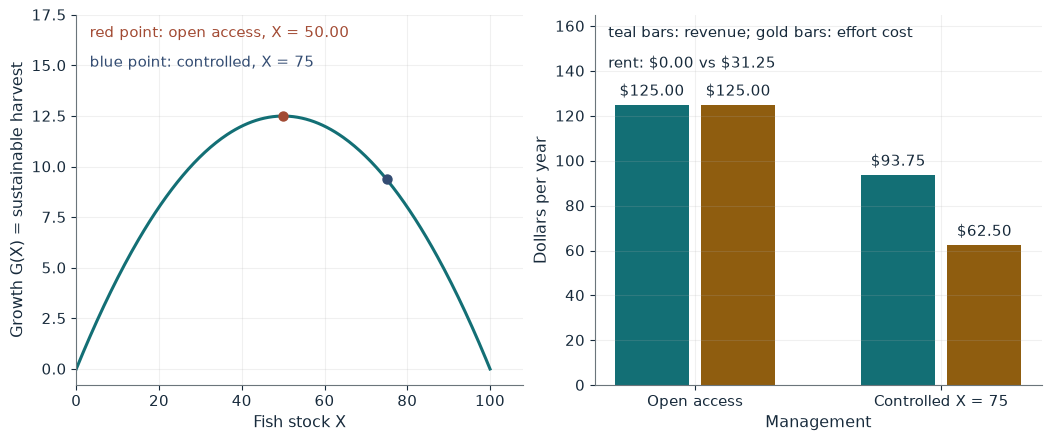

Open-access stock X_OA       50.00
Sustainable harvest          12.50
Effort E                     25.00
Revenue                      $125.00
Effort cost                  $125.00
Open-access rent             $0.00
Controlled harvest (X = 75)  9.3750
Controlled effort            12.50
Controlled rent              $31.25

Worked steps:
  1. X_OA = 5 / (0.01 x 10) = 50.00
  2. H = G(X_OA) = 0.5 x 50.00 x 0.50 = 12.50
  3. E = 12.50 / (0.01 x 50.00) = 25.00
  4. Revenue = 10 x 12.50 = $125.00; cost = 5 x 25.00 = $125.00; rent = $0.00
  5. Controlled X = 75: revenue = 10 x 9.375 = $93.75; cost = 5 x 12.5 = $62.50; rent = $31.25

Free entry pushes the stock to where a unit of effort just pays: 10 x 0.01 x X = 5, so X_OA = 50.00. Growth there is 12.50, which needs effort 12.50 / (0.01 x 50.00) = 25.00. Revenue $125.00 equals effort cost $125.00, so the rent is $0.00. At the controlled stock of 75, growth is 9.375 and effort 12.5, giving revenue $93.75 against cost $62.50, so holding the stock

In [2]:
show(fishery_picture(price=10, cost=5))

Change one input, `price`, and hold the others at the book's values:

In [3]:
sweep(fishery_picture, 'price', [7.5, 10, 15, 20], {'cost': 5}, ['Open-access stock X_OA', 'Effort E', 'Open-access rent', 'Controlled rent'])

price | Open-access stock X_OA | Effort E | Open-access rent | Controlled rent
7.5 | 66.6667 | 16.6667 | $0.00 | $7.81
10 | 50.00 | 25.00 | $0.00 | $31.25
15 | 33.3333 | 33.3333 | $0.00 | $78.12
20 | 25.00 | 37.50 | $0.00 | $125.00


Revenue and cost are both \$125, so the rent is zero. Holding the stock at 75 lands less fish (9.375) with half the effort (12.5) and earns \$31.25 a year. At a \$20 price entry pushes the stock to 25 and the rent is again zero.

## 2. Pigouvian correction: setting the corrective tax rate

With $MB(Q)=100-Q$, $MPC(Q)=20+Q$ and damage \$12 per unit, efficiency requires

$$100-Q=20+Q+12$$

so $Q^*=34$, while the untaxed market produces 40.

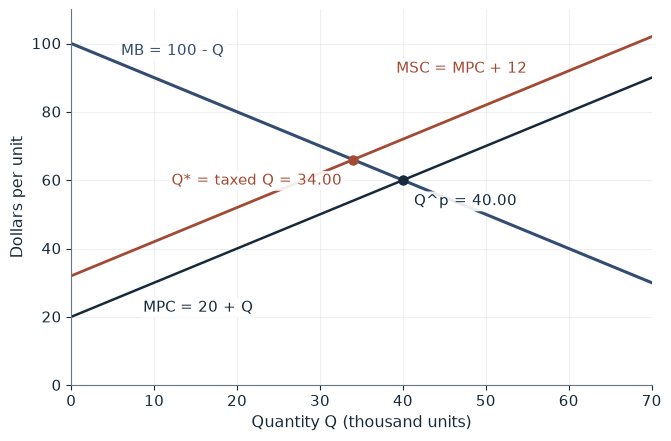

Untaxed output Q^p (000)      40.00
MSC at Q^p ($)                72.00
Efficient Q* (000)            34.00
Taxed output (000)            34.00
Taxed vs efficient            Efficient
Welfare loss, derived ($000)  0.00

Worked steps:
  1. Untaxed: 100 - Q = 20 + Q, so Q^p = 80 / 2 = 40.00
  2. MSC at Q^p = 20 + 40 + 12 = 72.00
  3. Efficient: 100 - Q = 20 + Q + 12, so Q* = 68 / 2 = 34.00
  4. Taxed: 100 - Q = 20 + Q + 12, so Q_t = 68 / 2 = 34.00
  5. Loss = 0.5 x 0.00 x (2 x 0.00) = 0.00 thousand dollars (derived)

With damage $12 per unit, the efficient quantity solves 100 - Q = 20 + Q + 12, so Q* = (80 - 12) / 2 = 34.00 thousand. A $12 tax gives (80 - 12) / 2 = 34.00 thousand, so output is efficient: the tax matches the damage. The shaded triangle between MB and MSC is the derived welfare loss, 0.00 thousand dollars; the book does not print this figure.


In [4]:
show(pigou_picture(damage=12, tax=12))

Change one input, `damage`, and hold the others at the book's values:

In [5]:
sweep(pigou_picture, 'damage', [0, 5, 12, 20], {'tax': 12}, ['Efficient Q* (000)', 'Taxed output (000)', 'Welfare loss, derived ($000)'])

damage | Efficient Q* (000) | Taxed output (000) | Welfare loss, derived ($000)
0 | 40.00 | 34.00 | 36.00
5 | 37.50 | 34.00 | 12.25
12 | 34.00 | 34.00 | 0.00
20 | 30.00 | 34.00 | 16.00


A \$12 tax matches the damage and gives 34 thousand units. If damage is really \$5, the efficient quantity is 37.5 and the same tax overshoots; the welfare-loss triangle, 12.25 thousand dollars, is derived from the linear schedules and is not printed in the book.

## 3. Prize contests: how many teams is too many?

Four teams each succeed with probability 0.25 and spend \$80,000; success is worth \$1,500,000.

$$q_4=1-0.75^4=0.68359375$$

$$W_4=0.68359375(1{,}500{,}000)-320{,}000=705{,}390.625$$

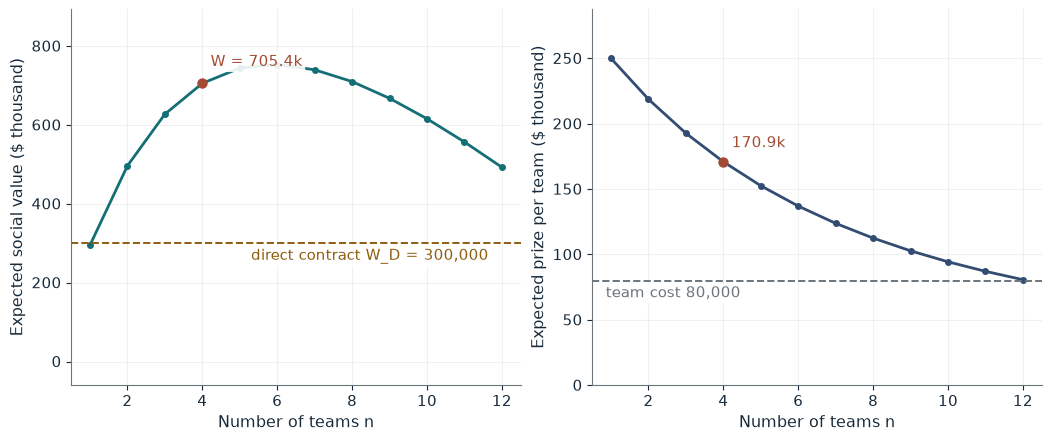

Success chance q_n         0.68359375
Total team cost            $320,000
Expected social value W_n  $705,390.625
Expected prize per team    $170,898.44
Direct contract W_D        $300,000
Teams enter                Yes

Worked steps:
  1. q = 1 - 0.75^4 = 0.6835937500
  2. W = 0.6835937500 x 1,500,000 - 4 x 80,000 = 1,025,390.625 - 320,000 = 705,390.625
  3. Prize per team = 0.6835937500 x 1,000,000 / 4 = 170,898.44
  4. W_D = 0.40 x 1,500,000 - 300,000 = 300,000

With 4 teams each succeeding with probability 0.25, the chance that at least one succeeds is 1 - 0.75^4 = 0.68359375, so expected social value is $705,390.625, above the direct contract's $300,000. Each team's expected prize, $170,898.44, covers its $80,000 cost, so teams want to enter.


In [6]:
show(prize_picture(teams=4, p=0.25))

Change one input, `teams`, and hold the others at the book's values:

In [7]:
sweep(prize_picture, 'teams', [1, 4, 8, 12], {'p': 0.25}, ['Success chance q_n', 'Expected social value W_n', 'Expected prize per team'])

teams | Success chance q_n | Expected social value W_n | Expected prize per team
1 | 0.25000000 | $295,000.000 | $250,000.00
4 | 0.68359375 | $705,390.625 | $170,898.44
8 | 0.89988708 | $709,830.627 | $112,485.89
12 | 0.96832365 | $492,485.472 | $80,693.64


Twelve teams lower expected value to \$492,485.472 (the book rounds $q_{12}$ and prints an approximate 492,485.475), yet each team still expects \$80,693.64, just above its cost, so private entry overshoots.

## 4. Tragedy of the commons: four users, one basin

Each user gets $B_i(x)=20x-x^2$ and bears a quarter of $D(X)=0.1X^2$. The private condition is

$$20-2x-\frac{0.2(4x)}{4}=0$$

and coordination maximizes $W(x)=4(20x-x^2)-0.1(4x)^2$.

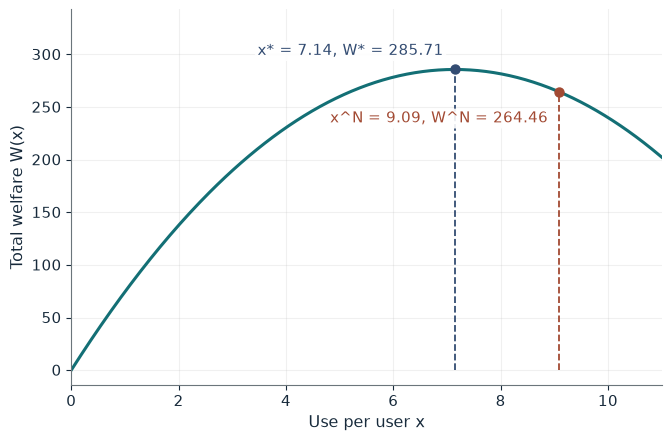

Private use per user x^N     9.09
Total private use X^N        36.36
Coordinated use per user x*  7.14
Total coordinated use X*     28.57
Welfare W^N                  264.46
Welfare W*                   285.71
Welfare gain                 21.25
Withdrawal cut               7.79

Worked steps:
  1. Private: 20 - 2x - 2 x 0.10 x = 0, so x^N = 20 / 2.20 = 9.0909
  2. Coordinated: 20 - 2x - 2 x 0.10 x 4 x = 0, so x* = 20 / 2.80 = 7.1429
  3. W^N = 4 x 9.090909 x (20 - 1.40 x 9.090909) = 264.46
  4. W* = 4 x 7.142857 x (20 - 1.40 x 7.142857) = 285.71
  5. Gain = 285.7143 - 264.4628 = 21.25; cut = 36.3636 - 28.5714 = 7.79

Each of the 4 users bears only 1/4 of the depletion cost, so privately each draws x^N = 20 / 2.20 = 9.09, 36.36 in total. Coordination counts the full cost and sets x* = 20 / 2.80 = 7.14, 28.57 in total. Cutting withdrawal by 7.79 raises welfare from 264.46 to 285.71, a gain of 21.25.


In [8]:
show(commons_picture(users=4, k=0.1))

Change one input, `users`, and hold the others at the book's values:

In [9]:
sweep(commons_picture, 'users', [2, 4, 8], {'k': 0.1}, ['Private use per user x^N', 'Coordinated use per user x*', 'Welfare gain'])

users | Private use per user x^N | Coordinated use per user x* | Welfare gain
2 | 9.09 | 8.33 | 1.38
4 | 9.09 | 7.14 | 21.25
8 | 9.09 | 5.56 | 179.98


Private use is 9.09 per user against 7.14 coordinated; cutting total withdrawal by 7.79 raises welfare by 21.25. More users leave private use unchanged but widen the gap.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

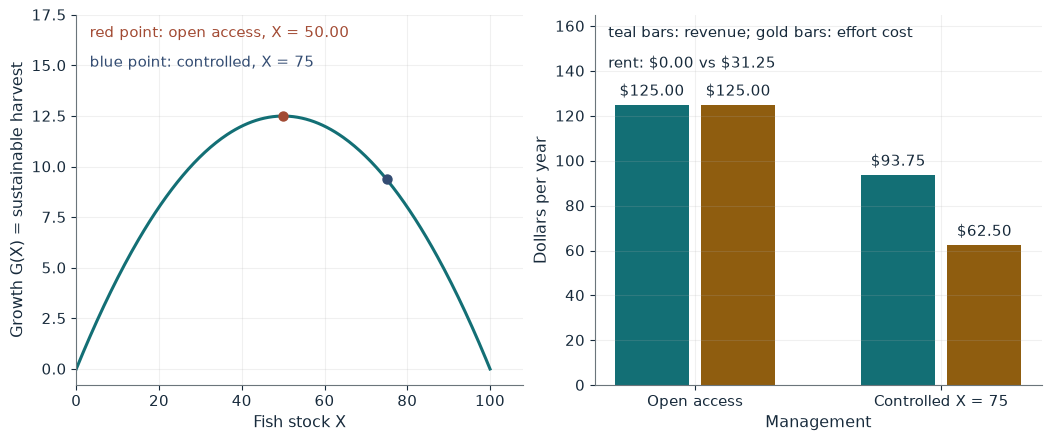

Open-access stock X_OA       50.00
Sustainable harvest          12.50
Effort E                     25.00
Revenue                      $125.00
Effort cost                  $125.00
Open-access rent             $0.00
Controlled harvest (X = 75)  9.3750
Controlled effort            12.50
Controlled rent              $31.25

Worked steps:
  1. X_OA = 5 / (0.01 x 10) = 50.00
  2. H = G(X_OA) = 0.5 x 50.00 x 0.50 = 12.50
  3. E = 12.50 / (0.01 x 50.00) = 25.00
  4. Revenue = 10 x 12.50 = $125.00; cost = 5 x 25.00 = $125.00; rent = $0.00
  5. Controlled X = 75: revenue = 10 x 9.375 = $93.75; cost = 5 x 12.5 = $62.50; rent = $31.25

Free entry pushes the stock to where a unit of effort just pays: 10 x 0.01 x X = 5, so X_OA = 50.00. Growth there is 12.50, which needs effort 12.50 / (0.01 x 50.00) = 25.00. Revenue $125.00 equals effort cost $125.00, so the rent is $0.00. At the controlled stock of 75, growth is 9.375 and effort 12.5, giving revenue $93.75 against cost $62.50, so holding the stock

In [10]:
show(fishery_picture(price=10, cost=5))

## Practice

**1.** With price \$10 and effort cost \$7.50, what is the open-access stock and the rent?

<details><summary>Answer</summary>

X_OA = 7.5 / (10 x 0.01) = 75; G(75) = 9.375; E = 12.5; revenue \$93.75 equals cost, so rent is 0.

</details>

**2.** With damage \$5 and a \$12 tax, how far is output from efficient?

<details><summary>Answer</summary>

Q* = 75 / 2 = 37.5 and Q_t = 68 / 2 = 34, so output is 3.5 thousand units too low; derived loss 12.25.

</details>

**3.** With 8 users and k = 0.1, what is the welfare gain from coordination?

<details><summary>Answer</summary>

x^N = 9.09 and x* = 20 / 3.6 = 5.56; W^N = 264.46 and W* = 444.44, a gain of 179.98.

</details>